# Entrenamiento del modelo RUL paso a paso

Este notebook recorre, paso a paso, el mismo proceso que ejecuta `train_model.py` para crear el modelo que estima la **Vida Útil Remanente (RUL)** de la prensa troqueladora.

| Paso | Qué se hace |
|---|---|
| 1 | Cargar la telemetría de 2025 y la bitácora de fallas |
| 2 | Explorar los datos |
| 3 | Calcular la columna objetivo `rul_dias` (cuenta regresiva hacia la siguiente falla) |
| 4 | Crear las 29 variables de entrada (ventanas móviles, tendencias, z-score, índice de estrés) |
| 5 | Separar entrenamiento y validación en orden cronológico (80 % / 20 %) |
| 6 | Entrenar el regresor XGBoost |
| 7 | Evaluar el modelo (MAE, RMSE, R², error en fase crítica) |
| 8 | Revisar qué variables pesan más |
| 9 | Comparar con el modelo guardado en `modelo_rul.joblib` |

> **Importante:** este notebook **no sobrescribe** `modelo_rul.joblib`. Entrena una copia en memoria para mostrar los pasos. Para regenerar el modelo oficial se sigue usando `python train_model.py`.

## 0. Librerías y parámetros

In [1]:
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (13, 4.5), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

Parámetros de la planta (los mismos de `train_model.py`):

- **600 muestras por día**: el turno va de 08:00 a 17:59 con una lectura por minuto. Por eso, en este proyecto, *1 día operativo = 600 filas = 10 horas*.
- **RUL máximo de 10 días**: si la siguiente falla está a más de 10 días, el objetivo se limita a 10.
- **Rangos nominales**: valores normales de fábrica de cada sensor. Se usan para medir cuánto se aleja cada lectura de lo normal.

In [2]:
FILE_TELEMETRIA = "telemetria_troqueladora.csv"
FILE_FALLAS = "log_fallas_mantenimiento.csv"

MUESTRAS_POR_TURNO_DIA = 600
MAX_RUL_DIAS = 10.0

SENSORES = ["temp_motor_c", "presion_hidraulica_bar", "vibracion_rms_mms", "corriente_motor_a"]

RANGOS_NOMINALES = {
    "temp_motor_c":           {"nominal_mean": 52.5,  "nominal_std": 2.0,  "alerta": 60.0,  "critico": 70.0,  "unidad": "°C"},
    "presion_hidraulica_bar": {"nominal_mean": 214.0, "nominal_std": 3.0,  "alerta": 200.0, "critico": 185.0, "unidad": "bar"},
    "vibracion_rms_mms":      {"nominal_mean": 1.35,  "nominal_std": 0.25, "alerta": 2.50,  "critico": 4.00,  "unidad": "mm/s"},
    "corriente_motor_a":      {"nominal_mean": 21.0,  "nominal_std": 1.2,  "alerta": 25.0,  "critico": 29.0,  "unidad": "A"},
}
NOMBRES = {"temp_motor_c": "Temperatura motor", "presion_hidraulica_bar": "Presión hidráulica",
           "vibracion_rms_mms": "Vibración RMS", "corriente_motor_a": "Corriente motor"}

## 1. Carga de datos

In [3]:
df = pd.read_csv(FILE_TELEMETRIA)
fallas = pd.read_csv(FILE_FALLAS)

df["dt"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("dt").reset_index(drop=True)
fallas["dt_falla"] = pd.to_datetime(fallas["timestamp_falla"])
fallas = fallas.sort_values("dt_falla").reset_index(drop=True)

print(f"Telemetría: {len(df):,} filas, de {df['dt'].min()} a {df['dt'].max()}")
print(f"Bitácora:   {len(fallas)} fallas registradas")
df.head()

Telemetría: 216,000 filas, de 2025-01-01 08:00:00 a 2025-12-26 17:59:00
Bitácora:   37 fallas registradas


,timestamp,temp_motor_c,presion_hidraulica_bar,vibracion_rms_mms,corriente_motor_a,dt
0,2025-01-01 08:00:00,52.60,216.84,1.25,20.16,2025-01-01 08:00:00
1,2025-01-01 08:01:00,51.83,211.33,1.31,19.92,2025-01-01 08:01:00
2,2025-01-01 08:02:00,52.78,214.24,1.40,21.48,2025-01-01 08:02:00
3,2025-01-01 08:03:00,53.83,215.16,1.15,21.09,2025-01-01 08:03:00
4,2025-01-01 08:04:00,51.72,215.65,1.31,20.55,2025-01-01 08:04:00


In [4]:
fallas[["id_parada", "timestamp_falla", "tipo_falla", "componente_afectado", "duracion_parada_min"]].head(10)

,id_parada,timestamp_falla,tipo_falla,componente_afectado,duracion_parada_min
0,PAR-001,2025-01-14 17:59:00,Sobrecarga Electrica y Friccion Excesiva,Guias Deslizantes y Estator,840
1,PAR-002,2025-01-19 17:59:00,Falla Critica por Desbalance y Vibracion en Ro...,Rodamiento Principal de Apoyo,840
2,PAR-003,2025-01-21 17:59:00,Falla Critica por Desbalance y Vibracion en Ro...,Rodamiento Principal de Apoyo,840
3,PAR-004,2025-01-22 17:59:00,Sobrecarga Electrica y Friccion Excesiva,Guias Deslizantes y Estator,840
4,PAR-005,2025-01-25 17:59:00,Sobrecarga Electrica y Friccion Excesiva,Guias Deslizantes y Estator,840
5,PAR-006,2025-01-28 17:59:00,Sobrecarga Electrica y Friccion Excesiva,Guias Deslizantes y Estator,840
6,PAR-007,2025-02-11 17:59:00,Sobrecarga Electrica y Friccion Excesiva,Guias Deslizantes y Estator,840
7,PAR-008,2025-02-16 17:59:00,Sobrecarga Electrica y Friccion Excesiva,Guias Deslizantes y Estator,840
8,PAR-009,2025-02-27 17:59:00,Fatiga Mecanica y Vibracion en Bancada,Cojinetes de Cabeza de Biela,840
9,PAR-010,2025-03-16 17:59:00,Sobrecarga Electrica y Friccion Excesiva,Guias Deslizantes y Estator,840


## 2. Exploración de los datos

### 2.1 Calidad: vacíos, duplicados y lecturas por día

In [5]:
lecturas_por_dia = df.groupby(df["dt"].dt.date).size()
print("Valores vacíos:        ", int(df[SENSORES].isna().sum().sum()))
print("Marcas de tiempo repetidas:", int(df["dt"].duplicated().sum()))
print("Días registrados:      ", lecturas_por_dia.size)
print("Lecturas por día:      ", lecturas_por_dia.value_counts().to_dict())

Valores vacíos:         0
Marcas de tiempo repetidas: 0
Días registrados:       360
Lecturas por día:       {600: 360}


### 2.2 Estadística descriptiva frente a los rangos nominales

In [6]:
resumen = df[SENSORES].describe().T[["mean", "std", "min", "50%", "max"]]
resumen["nominal"] = [RANGOS_NOMINALES[s]["nominal_mean"] for s in SENSORES]
resumen["alerta"] = [RANGOS_NOMINALES[s]["alerta"] for s in SENSORES]
resumen["crítico"] = [RANGOS_NOMINALES[s]["critico"] for s in SENSORES]
resumen.round(2)

,mean,std,min,50%,max,nominal,alerta,crítico
temp_motor_c,56.55,7.87,46.75,52.91,98.45,52.50,60.0,70.0
presion_hidraulica_bar,209.56,10.10,154.55,213.79,239.97,214.00,200.0,185.0
vibracion_rms_mms,1.92,1.13,0.72,1.39,8.12,1.35,2.5,4.0
corriente_motor_a,23.02,3.60,18.24,21.43,42.14,21.00,25.0,29.0


### 2.3 Fallas por tipo

In [7]:
fallas["tipo_falla"].value_counts().to_frame("cantidad")

,cantidad
tipo_falla,
Sobrecarga Electrica y Friccion Excesiva,26
Falla Critica por Desbalance y Vibracion en Rodamiento,7
Fatiga Mecanica y Vibracion en Bancada,4


### 2.4 Los sensores durante el año

Cada punto es el **promedio diario** de un sensor. Las líneas verticales rojas marcan las fallas de la bitácora.

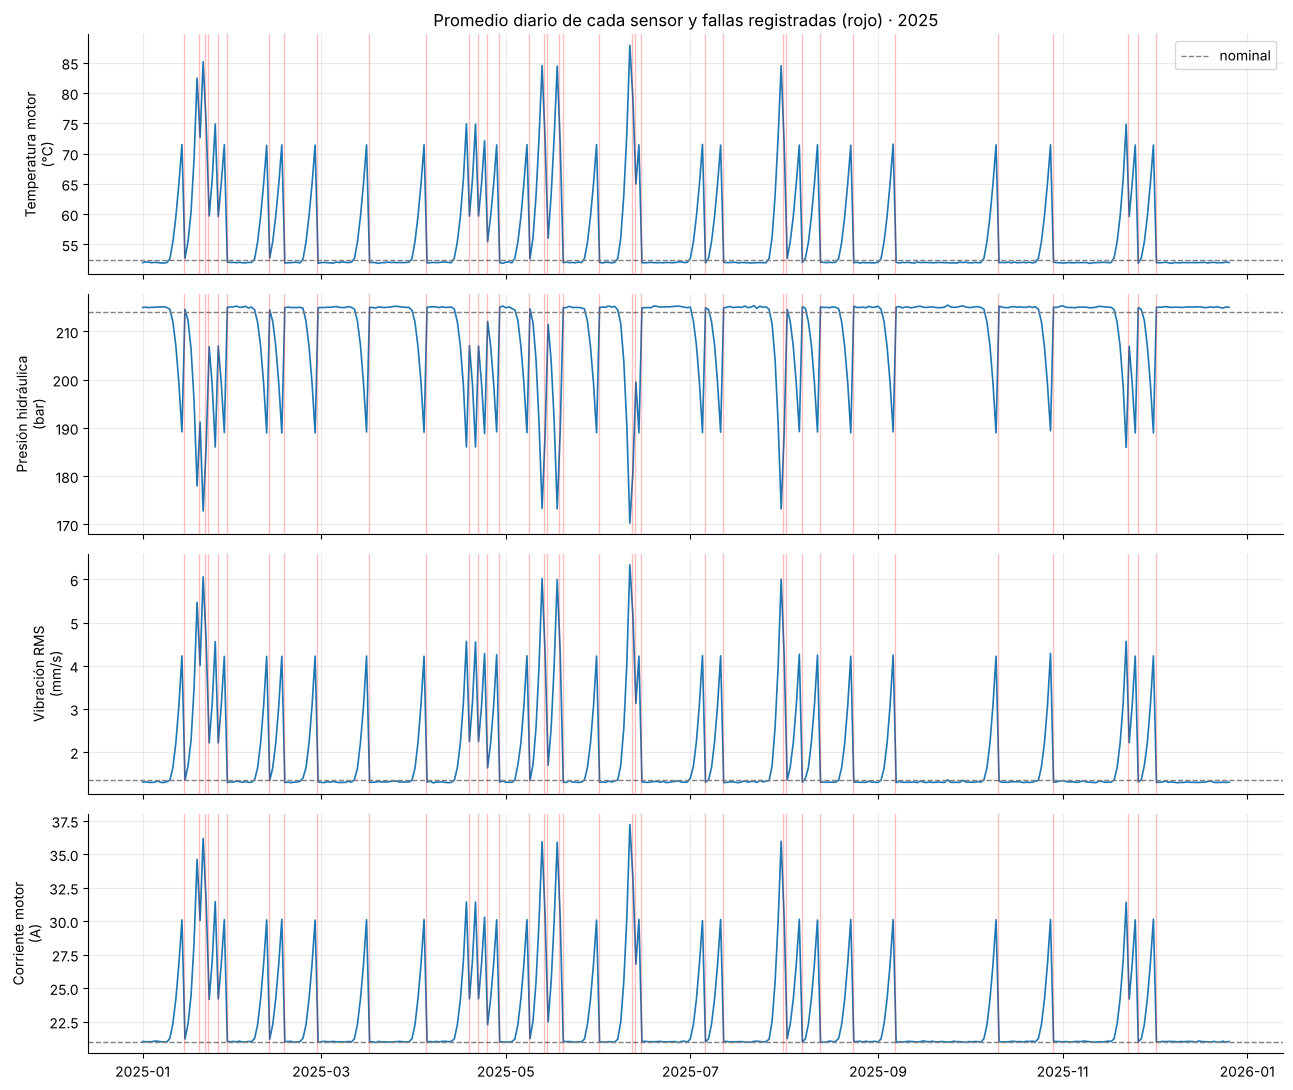

In [8]:
diario = df.set_index("dt")[SENSORES].resample("D").mean().dropna()
fig, axes = plt.subplots(4, 1, figsize=(13, 11), sharex=True)
for ax, s in zip(axes, SENSORES):
    ax.plot(diario.index, diario[s], lw=1.2)
    ax.axhline(RANGOS_NOMINALES[s]["nominal_mean"], color="gray", ls="--", lw=1, label="nominal")
    for f in fallas["dt_falla"]:
        ax.axvline(f, color="red", alpha=0.25, lw=1)
    ax.set_ylabel(f"{NOMBRES[s]}\n({RANGOS_NOMINALES[s]['unidad']})")
axes[0].legend(loc="upper right")
axes[0].set_title("Promedio diario de cada sensor y fallas registradas (rojo) · 2025")
plt.tight_layout(); plt.show()

### 2.5 Zoom: los días previos a una falla

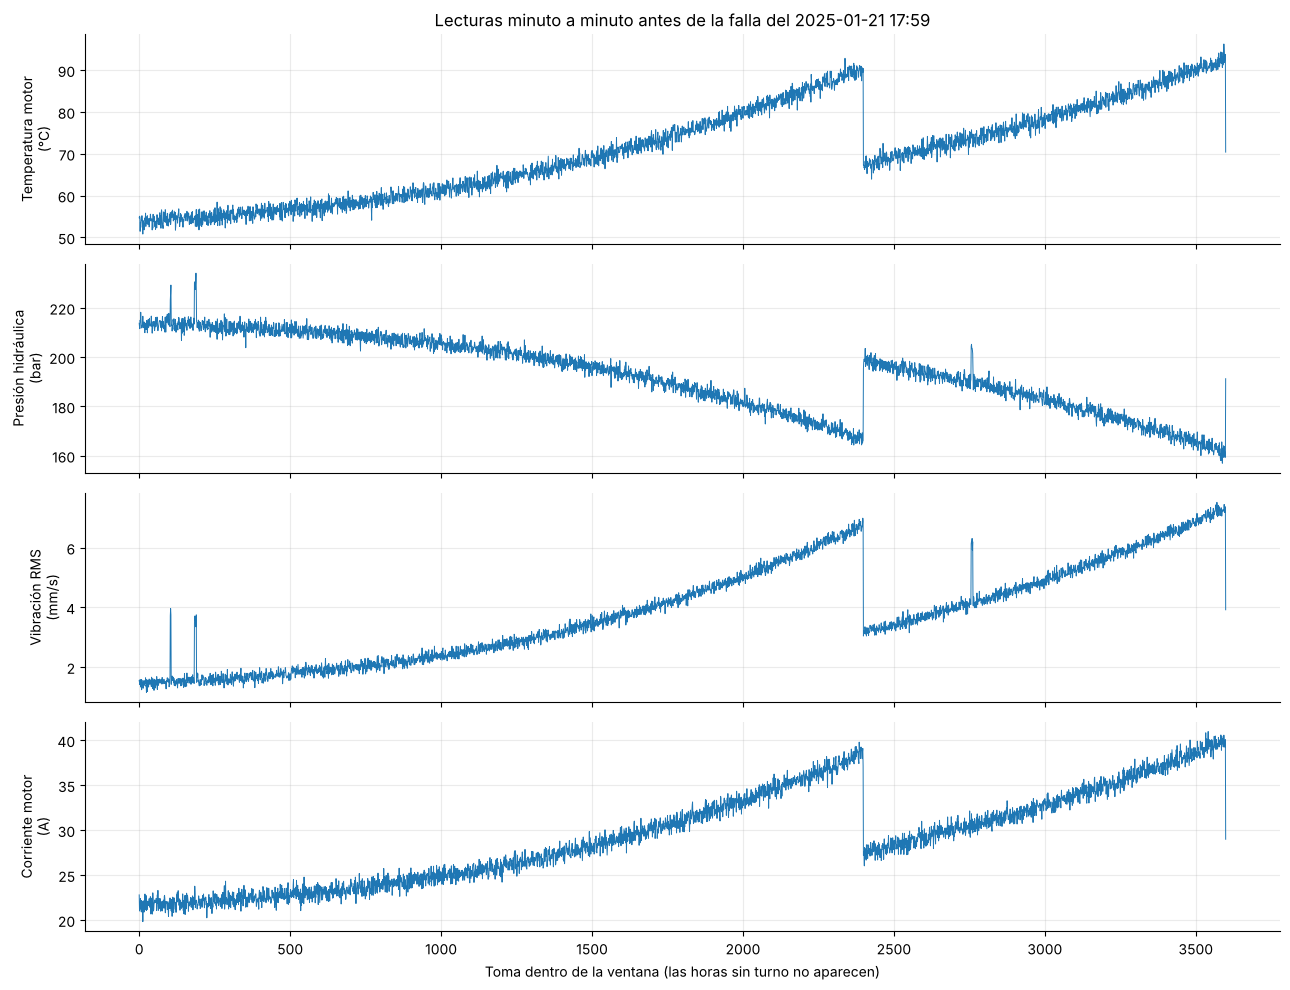

In [9]:
falla_ej = fallas["dt_falla"].iloc[2]
ventana = df[(df["dt"] > falla_ej - pd.Timedelta(days=6)) & (df["dt"] <= falla_ej)].reset_index(drop=True)
fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
for ax, s in zip(axes, SENSORES):
    ax.plot(ventana.index, ventana[s], lw=0.7)
    ax.set_ylabel(f"{NOMBRES[s]}\n({RANGOS_NOMINALES[s]['unidad']})")
axes[0].set_title(f"Lecturas minuto a minuto antes de la falla del {falla_ej:%Y-%m-%d %H:%M}")
axes[-1].set_xlabel("Toma dentro de la ventana (las horas sin turno no aparecen)")
plt.tight_layout(); plt.show()

## 3. Cálculo del objetivo: `rul_dias`

Para cada lectura se busca **la siguiente falla de la bitácora** y se cuenta cuántas filas faltan hasta ella:

$$RUL = \min\left(\frac{\text{filas hasta la siguiente falla}}{600},\ 10\right)$$

- Se cuentan **filas**, no horas de reloj: la noche entre turnos no suma tiempo.
- Las lecturas **después de la última falla** no tienen siguiente falla conocida; el código les asigna 10 días.

In [10]:
# 3.1 Posición (fila) de cada falla dentro de la telemetría
falla_indices = []
for ts in fallas["dt_falla"]:
    coincidencia = df.index[df["dt"] == ts]
    falla_indices.append(coincidencia[0] if len(coincidencia) else (df["dt"] - ts).abs().idxmin())
falla_indices = np.sort(np.unique(falla_indices))
print(f"Fallas ubicadas en la serie: {len(falla_indices)}")
print("Primeras posiciones:", falla_indices[:5])

Fallas ubicadas en la serie: 37
Primeras posiciones: [ 8399 11399 12599 13199 14999]


In [11]:
# 3.2 Para cada fila, la posición de la siguiente falla
idx = df.index.values
pos_siguiente = np.searchsorted(falla_indices, idx, side="left")
tiene_siguiente = pos_siguiente < len(falla_indices)

# 3.3 Cuenta regresiva en días operativos, limitada a 10
rul = np.full(len(df), MAX_RUL_DIAS)
filas_restantes = falla_indices[pos_siguiente[tiene_siguiente]] - idx[tiene_siguiente]
rul[tiene_siguiente] = np.clip(filas_restantes / MUESTRAS_POR_TURNO_DIA, 0, MAX_RUL_DIAS)
df["rul_dias"] = rul

print(f"RUL mínimo {df['rul_dias'].min():.2f} · mediana {df['rul_dias'].median():.2f} · máximo {df['rul_dias'].max():.2f} días")
print(f"Filas con RUL < 10 (degradación activa): {(df['rul_dias'] < 10).sum():,} ({(df['rul_dias'] < 10).mean():.1%})")
print(f"Filas después de la última falla (sin siguiente falla conocida): {(~tiene_siguiente).sum():,}")

RUL mínimo 0.00 · mediana 6.87 · máximo 10.00 días
Filas con RUL < 10 (degradación activa): 138,000 (63.9%)
Filas después de la última falla (sin siguiente falla conocida): 15,000


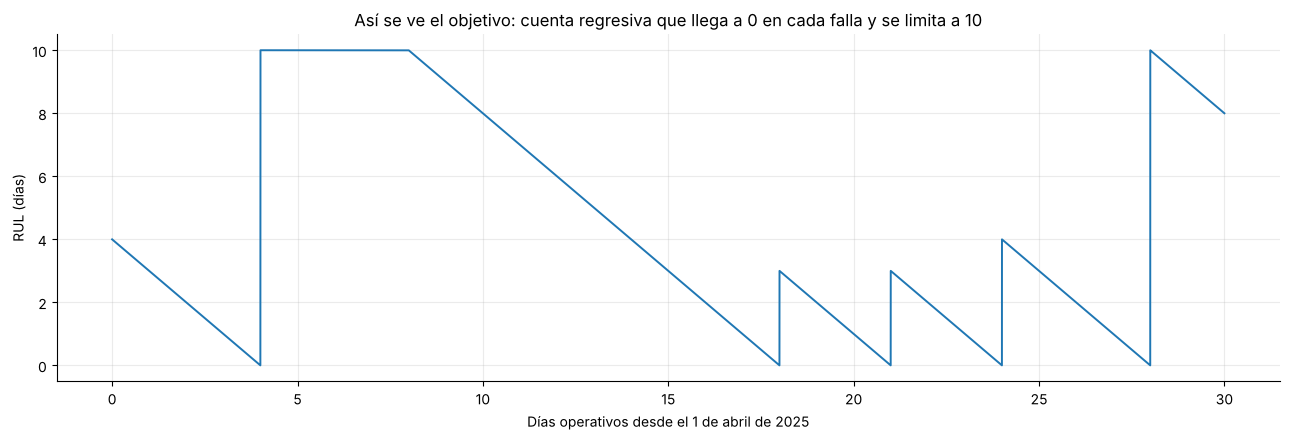

In [12]:
tramo = df[(df["dt"] >= "2025-04-01") & (df["dt"] < "2025-05-01")].reset_index(drop=True)
fig, ax = plt.subplots()
ax.plot(tramo.index / MUESTRAS_POR_TURNO_DIA, tramo["rul_dias"], lw=1.4)
ax.set_xlabel("Días operativos desde el 1 de abril de 2025")
ax.set_ylabel("RUL (días)")
ax.set_title("Así se ve el objetivo: cuenta regresiva que llega a 0 en cada falla y se limita a 10")
plt.tight_layout(); plt.show()

## 4. Ingeniería de variables (29 variables)

Una lectura aislada puede ser ruido. Por eso, para cada sensor se calculan 7 variables que describen su **comportamiento reciente**:

| Variable | Qué mide |
|---|---|
| `s` | Valor instantáneo |
| `s_mean_15`, `s_mean_60` | Media de los últimos 15 y 60 minutos: suaviza picos aislados |
| `s_std_60` | Desviación estándar de los últimos 60 minutos: inestabilidad de la señal |
| `s_trend_15`, `s_trend_60` | Diferencia con el valor de hace 15 y 60 minutos: si sube o baja |
| `s_zscore_nom` | Cuántas desviaciones nominales se aleja `s_mean_60` del valor normal |

4 sensores × 7 = 28 variables, más un **índice de estrés termomecánico** que combina los cuatro sensores: 29 en total.

> Las ventanas solo miran hacia atrás, así que no usan información del futuro. Nota: como se trabaja por filas, la ventana de las 08:00 incluye lecturas del final del turno anterior.

In [13]:
feature_cols = []
for s in SENSORES:
    df[f"{s}_mean_15"] = df[s].rolling(15, min_periods=1).mean()
    df[f"{s}_mean_60"] = df[s].rolling(60, min_periods=1).mean()
    df[f"{s}_std_60"] = df[s].rolling(60, min_periods=1).std().fillna(0.0)
    df[f"{s}_trend_60"] = df[s] - df[s].shift(60).bfill()
    df[f"{s}_trend_15"] = df[s] - df[s].shift(15).bfill()
    nom = RANGOS_NOMINALES[s]
    df[f"{s}_zscore_nom"] = (df[f"{s}_mean_60"] - nom["nominal_mean"]) / nom["nominal_std"]
    feature_cols += [s, f"{s}_mean_15", f"{s}_mean_60", f"{s}_std_60",
                     f"{s}_trend_60", f"{s}_trend_15", f"{s}_zscore_nom"]

# Índice de estrés: solo suman las desviaciones en la dirección peligrosa
# (más temperatura, más vibración, MENOS presión, más corriente)
df["indice_estres_termomecanico"] = (
    np.maximum(0,  df["temp_motor_c_zscore_nom"]) * 0.30 +
    np.maximum(0,  df["vibracion_rms_mms_zscore_nom"]) * 0.35 +
    np.maximum(0, -df["presion_hidraulica_bar_zscore_nom"]) * 0.20 +
    np.maximum(0,  df["corriente_motor_a_zscore_nom"]) * 0.15
)
feature_cols.append("indice_estres_termomecanico")
print(f"Variables de entrada: {len(feature_cols)}")
df[feature_cols[:7]].describe().T.round(3)

Variables de entrada: 29


,count,mean,std,min,25%,50%,75%,max
temp_motor_c,216000.0,56.547,7.867,46.750,51.690,52.910,58.920,98.450
temp_motor_c_mean_15,216000.0,56.547,7.767,50.720,51.929,52.275,58.932,96.259
temp_motor_c_mean_60,216000.0,56.547,7.719,51.404,51.967,52.145,58.996,95.216
temp_motor_c_std_60,216000.0,1.282,0.843,0.000,1.125,1.202,1.278,11.883
temp_motor_c_trend_60,216000.0,-0.000,2.869,-28.310,-0.980,0.210,1.390,8.890
temp_motor_c_trend_15,216000.0,-0.000,2.056,-28.730,-1.090,0.050,1.200,7.580
temp_motor_c_zscore_nom,216000.0,2.023,3.859,-0.548,-0.266,-0.178,3.248,21.358


### 4.1 Cómo suavizan las medias móviles (vibración, un día)

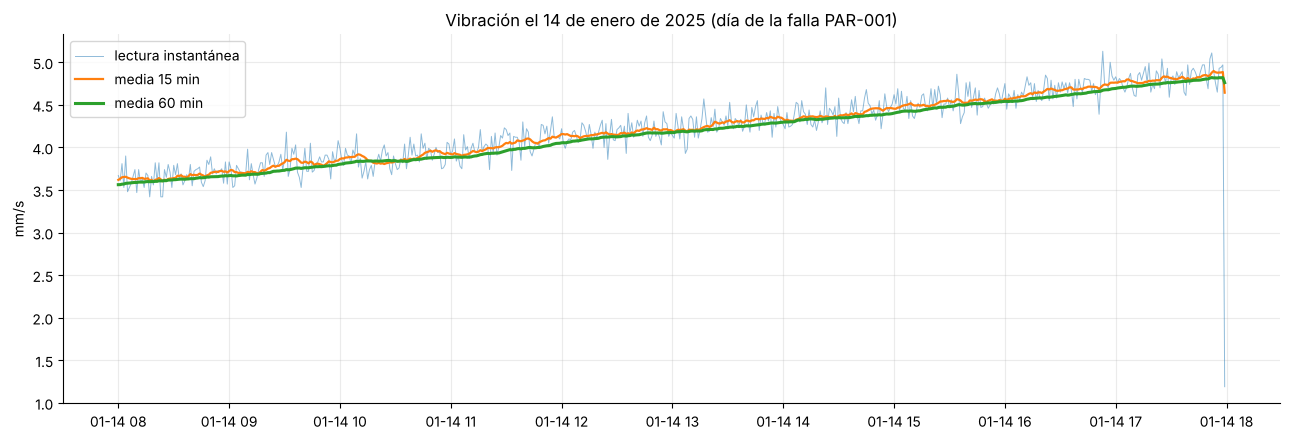

In [14]:
dia = df[df["dt"].dt.date == pd.Timestamp("2025-01-14").date()]
fig, ax = plt.subplots()
ax.plot(dia["dt"], dia["vibracion_rms_mms"], lw=0.7, alpha=0.5, label="lectura instantánea")
ax.plot(dia["dt"], dia["vibracion_rms_mms_mean_15"], lw=1.6, label="media 15 min")
ax.plot(dia["dt"], dia["vibracion_rms_mms_mean_60"], lw=2.2, label="media 60 min")
ax.set_ylabel("mm/s"); ax.legend()
ax.set_title("Vibración el 14 de enero de 2025 (día de la falla PAR-001)")
plt.tight_layout(); plt.show()

### 4.2 El índice de estrés frente al RUL

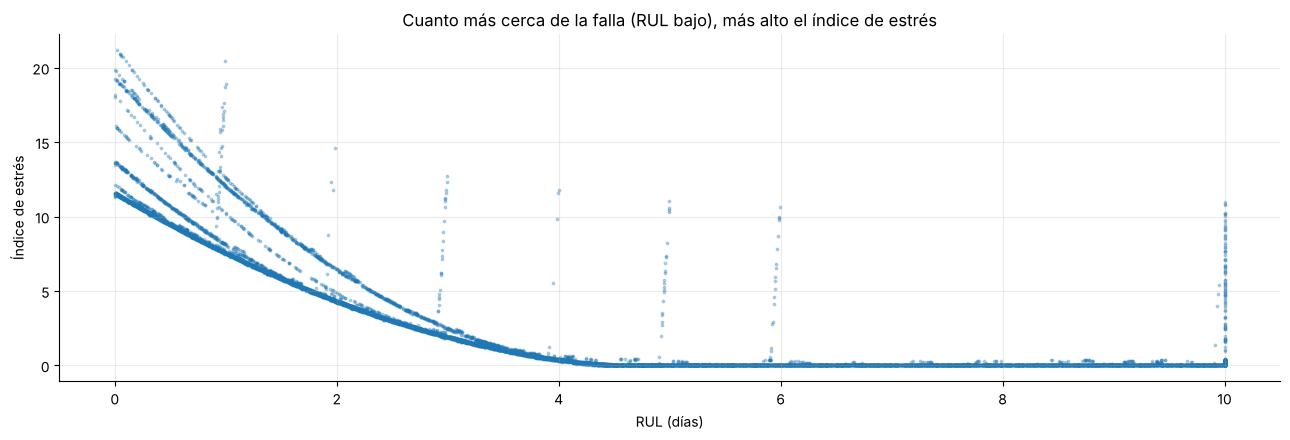

In [15]:
muestra = df.sample(20_000, random_state=0)
fig, ax = plt.subplots()
ax.scatter(muestra["rul_dias"], muestra["indice_estres_termomecanico"], s=3, alpha=0.3)
ax.set_xlabel("RUL (días)"); ax.set_ylabel("Índice de estrés")
ax.set_title("Cuanto más cerca de la falla (RUL bajo), más alto el índice de estrés")
plt.tight_layout(); plt.show()

### 4.3 Correlación de cada variable con el RUL

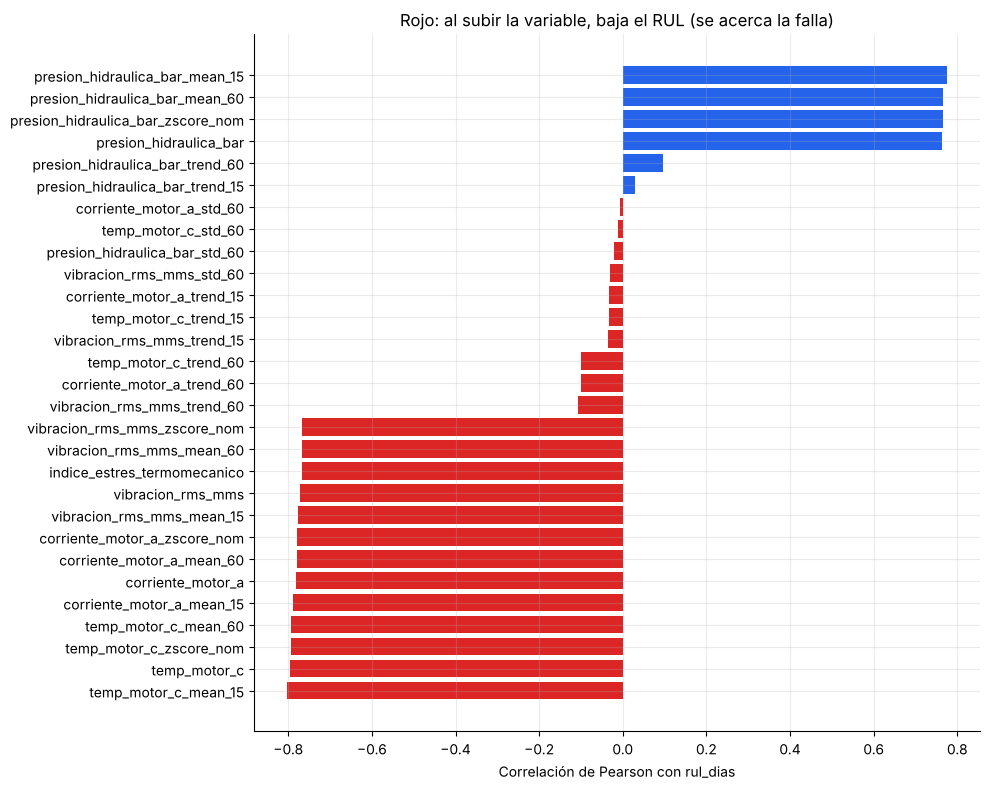

In [16]:
corr = df[feature_cols + ["rul_dias"]].corr()["rul_dias"].drop("rul_dias").sort_values()
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(corr.index, corr.values, color=np.where(corr.values < 0, "#dc2626", "#2563eb"))
ax.set_xlabel("Correlación de Pearson con rul_dias")
ax.set_title("Rojo: al subir la variable, baja el RUL (se acerca la falla)")
plt.tight_layout(); plt.show()

## 5. Partición cronológica: 80 % entrenamiento / 20 % validación

En series de tiempo **no** se mezclan las filas al azar: el modelo aprende con el pasado y se evalúa con el futuro, como pasaría en la planta.

In [17]:
split_idx = int(len(df) * 0.80)
train_df, test_df = df.iloc[:split_idx], df.iloc[split_idx:]
X_train, y_train = train_df[feature_cols], train_df["rul_dias"]
X_test, y_test = test_df[feature_cols], test_df["rul_dias"]

print(f"Entrenamiento: {len(train_df):,} filas ({train_df['dt'].min():%Y-%m-%d} a {train_df['dt'].max():%Y-%m-%d})")
print(f"Validación:    {len(test_df):,} filas ({test_df['dt'].min():%Y-%m-%d} a {test_df['dt'].max():%Y-%m-%d})")
print(f"Fallas en entrenamiento: {(fallas['dt_falla'] <= train_df['dt'].max()).sum()} · en validación: {(fallas['dt_falla'] > train_df['dt'].max()).sum()}")

Entrenamiento: 172,800 filas (2025-01-01 a 2025-10-15)
Validación:    43,200 filas (2025-10-16 a 2025-12-26)
Fallas en entrenamiento: 33 · en validación: 4


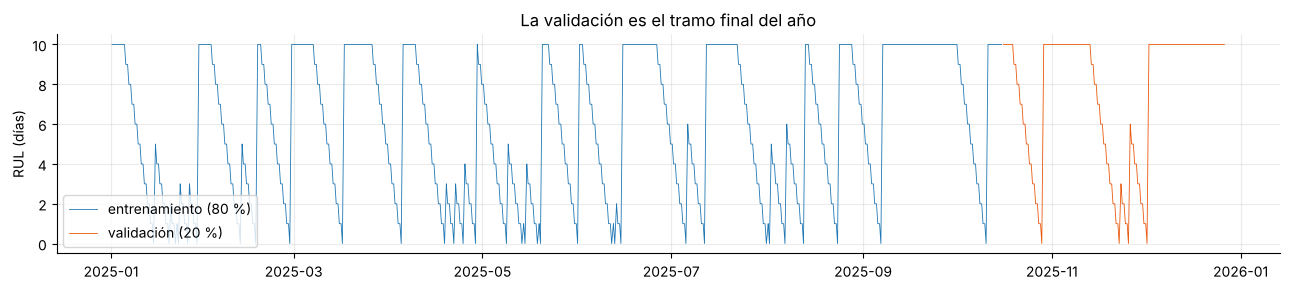

In [18]:
fig, ax = plt.subplots(figsize=(13, 3))
ax.plot(train_df["dt"], train_df["rul_dias"], lw=0.6, label="entrenamiento (80 %)")
ax.plot(test_df["dt"], test_df["rul_dias"], lw=0.6, color="#ea580c", label="validación (20 %)")
ax.set_ylabel("RUL (días)"); ax.legend(loc="lower left")
ax.set_title("La validación es el tramo final del año")
plt.tight_layout(); plt.show()

## 6. Entrenamiento del modelo XGBoost

XGBoost construye **muchos árboles de decisión pequeños, uno tras otro**: cada árbol nuevo intenta corregir el error que dejaron los anteriores.

| Hiperparámetro | Valor | Significado |
|---|---|---|
| `n_estimators` | 180 | Número de árboles |
| `max_depth` | 6 | Profundidad máxima de cada árbol |
| `learning_rate` | 0.08 | Cuánto corrige cada árbol nuevo |
| `subsample` | 0.85 | Fracción de filas que ve cada árbol |
| `colsample_bytree` | 0.85 | Fracción de variables que ve cada árbol |

In [19]:
modelo = XGBRegressor(n_estimators=180, max_depth=6, learning_rate=0.08,
                      subsample=0.85, colsample_bytree=0.85, n_jobs=-1, random_state=42)
t0 = time.time()
modelo.fit(X_train, y_train)
print(f"Entrenamiento completado en {time.time() - t0:.1f} s")

Entrenamiento completado en 1.2 s


## 7. Evaluación en el 20 % de validación

- **MAE**: error absoluto medio, en días.
- **RMSE**: castiga más los errores grandes.
- **R²**: qué parte de la variación del RUL explica el modelo (1 = perfecto).
- **Fase crítica**: solo las filas con RUL ≤ 3 días, donde una buena estimación importa más.

Las predicciones se recortan a 0–10 días, igual que el objetivo.

In [20]:
y_pred = np.clip(modelo.predict(X_test), 0, MAX_RUL_DIAS)
critica = y_test <= 3.0

metricas = pd.DataFrame({
    "MAE (días)": [mean_absolute_error(y_test, y_pred), mean_absolute_error(y_test[critica], y_pred[critica])],
    "RMSE (días)": [np.sqrt(mean_squared_error(y_test, y_pred)), np.sqrt(mean_squared_error(y_test[critica], y_pred[critica]))],
    "R²": [r2_score(y_test, y_pred), np.nan],
    "filas": [len(y_test), int(critica.sum())],
}, index=["Global", "Fase crítica (RUL ≤ 3)"])
metricas["MAE (horas operativas)"] = metricas["MAE (días)"] * 10
metricas.round(4)

,MAE (días),RMSE (días),R²,filas,MAE (horas operativas)
Global,1.1326,1.4337,0.8169,43200,11.3257
Fase crítica (RUL ≤ 3),0.0498,0.0824,NaN,7203,0.4984


### 7.1 Predicción frente a valor real a lo largo de la validación

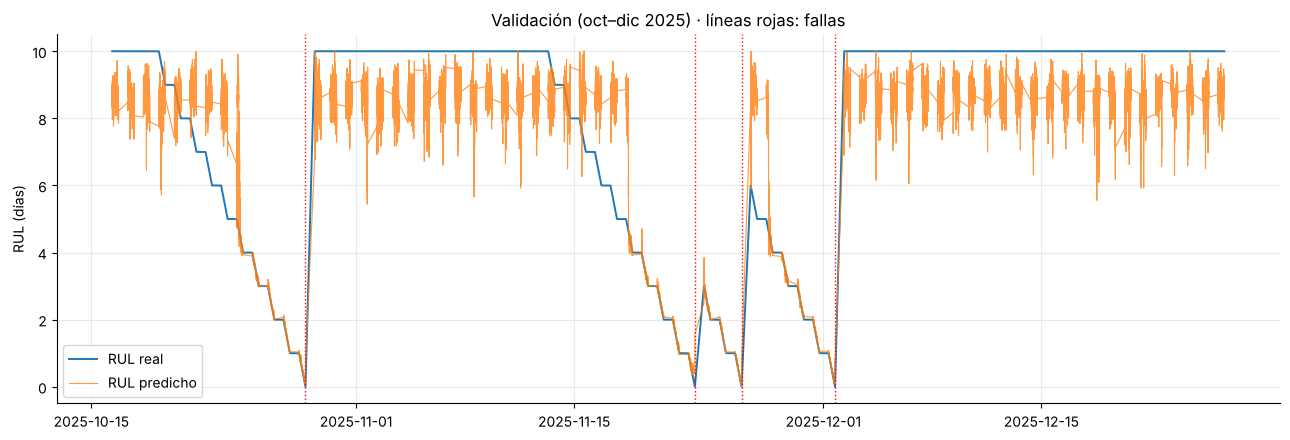

In [21]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(test_df["dt"].values, y_test.values, lw=1.4, label="RUL real")
ax.plot(test_df["dt"].values, y_pred, lw=0.8, alpha=0.8, label="RUL predicho")
for f in fallas.loc[fallas["dt_falla"] > train_df["dt"].max(), "dt_falla"]:
    ax.axvline(f, color="red", ls=":", lw=1)
ax.set_ylabel("RUL (días)"); ax.legend(loc="lower left")
ax.set_title("Validación (oct–dic 2025) · líneas rojas: fallas")
plt.tight_layout(); plt.show()

### 7.2 Dispersión real vs. predicho

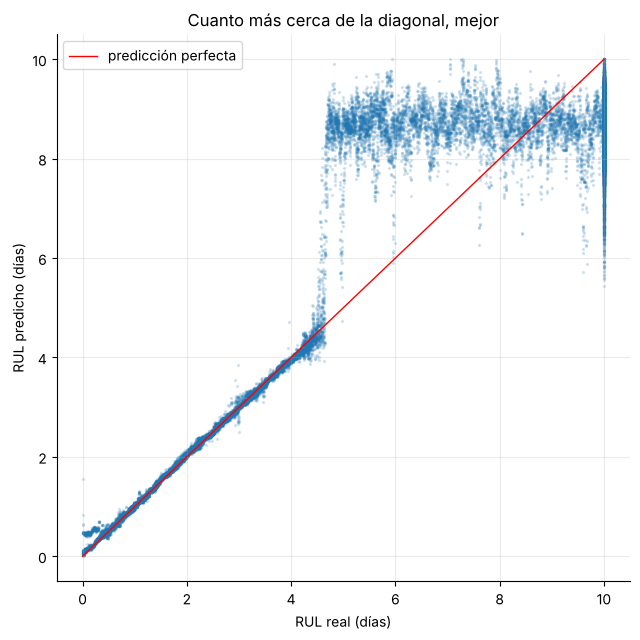

In [22]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(y_test, y_pred, s=2, alpha=0.15)
ax.plot([0, 10], [0, 10], color="red", lw=1, label="predicción perfecta")
ax.set_xlabel("RUL real (días)"); ax.set_ylabel("RUL predicho (días)"); ax.legend()
ax.set_title("Cuanto más cerca de la diagonal, mejor")
plt.tight_layout(); plt.show()

### 7.3 Error según la distancia a la falla

El error **no es igual** en todo el rango. Aquí se agrupa por días restantes (solo filas con una falla siguiente conocida a menos de 10 días). El *sesgo* positivo significa que el modelo **cree que queda más vida de la real** (alerta tardía).

In [23]:
pos = np.searchsorted(falla_indices, test_df.index.values, side="left")
conocida = pos < len(falla_indices)
rul_sin_tope = np.full(len(test_df), np.nan)
rul_sin_tope[conocida] = (falla_indices[pos[conocida]] - test_df.index.values[conocida]) / MUESTRAS_POR_TURNO_DIA

eval_df = pd.DataFrame({"real": y_test.values, "pred": y_pred, "sin_tope": rul_sin_tope})
eval_df = eval_df[eval_df["sin_tope"] < 10].copy()
eval_df["intervalo"] = pd.cut(eval_df["sin_tope"], bins=np.arange(0, 11), include_lowest=True)
eval_df["error"] = eval_df["pred"] - eval_df["real"]
por_intervalo = eval_df.groupby("intervalo", observed=True).agg(
    filas=("error", "size"),
    mae_horas=("error", lambda e: e.abs().mean() * 10),
    sesgo_horas=("error", lambda e: e.mean() * 10),
).round(2)
por_intervalo

,filas,mae_horas,sesgo_horas
intervalo,,,
"(-0.001, 1.0]",2404,0.69,0.60
"(1.0, 2.0]",2400,0.37,0.29
"(2.0, 3.0]",2399,0.43,0.26
"(3.0, 4.0]",1800,0.42,-0.10
"(4.0, 5.0]",1800,13.92,12.98
"(5.0, 6.0]",1799,31.56,31.56
"(6.0, 7.0]",1200,21.85,21.85
"(7.0, 8.0]",1200,13.18,13.00
"(8.0, 9.0]",1200,3.73,1.17


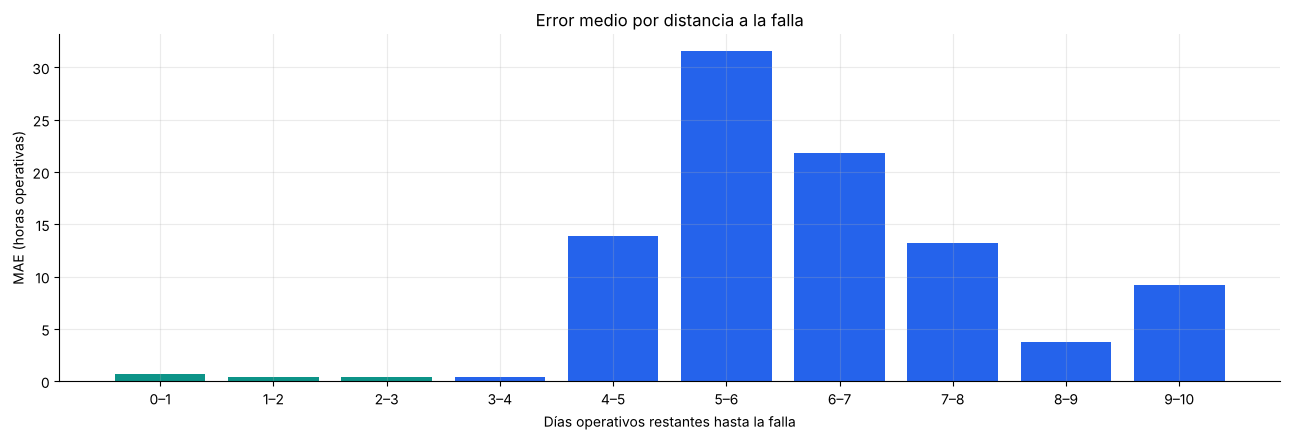

In [24]:
fig, ax = plt.subplots()
etiquetas = [f"{int(i.left)}–{int(i.right)}" for i in por_intervalo.index]
ax.bar(etiquetas, por_intervalo["mae_horas"], color=["#0d9488"] * 3 + ["#2563eb"] * (len(etiquetas) - 3))
ax.set_xlabel("Días operativos restantes hasta la falla"); ax.set_ylabel("MAE (horas operativas)")
ax.set_title("Error medio por distancia a la falla")
plt.tight_layout(); plt.show()

## 8. Importancia de las variables

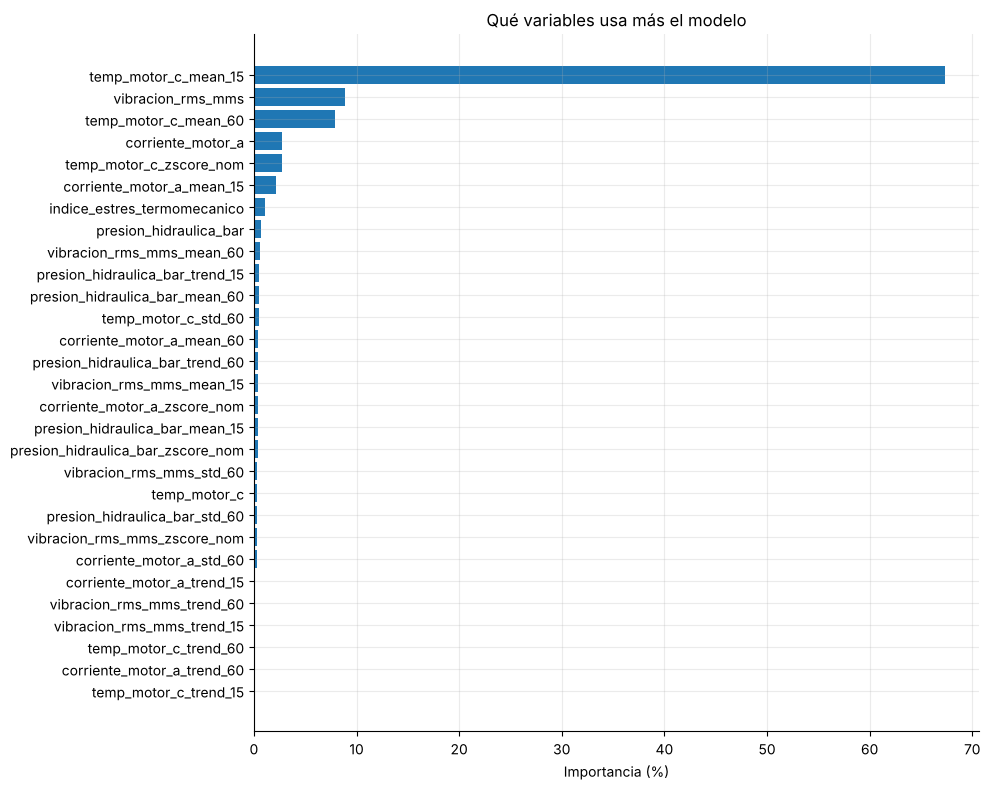

,importancia (%)
temp_motor_c_mean_15,67.300003
vibracion_rms_mms,8.880000
temp_motor_c_mean_60,7.880000
corriente_motor_a,2.730000
temp_motor_c_zscore_nom,2.710000
corriente_motor_a_mean_15,2.180000
indice_estres_termomecanico,1.040000


In [25]:
importancia = pd.Series(modelo.feature_importances_, index=feature_cols).sort_values()
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(importancia.index, importancia.values * 100)
ax.set_xlabel("Importancia (%)")
ax.set_title("Qué variables usa más el modelo")
plt.tight_layout(); plt.show()
(importancia.sort_values(ascending=False).head(7) * 100).round(2).to_frame("importancia (%)")

## 9. Comparación con el modelo guardado (`modelo_rul.joblib`)

Se carga el modelo oficial y se comprueba que usa las mismas variables y que sus métricas coinciden con las de este notebook. Pueden aparecer diferencias mínimas si la versión de XGBoost es distinta a la usada al entrenarlo.

In [26]:
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    bundle = joblib.load("modelo_rul.joblib")

print("Mismas variables y en el mismo orden:", bundle["feature_cols"] == feature_cols)
print("Fecha de entrenamiento del modelo guardado:", bundle["fecha_entrenamiento"])

pred_guardado = np.clip(bundle["modelo"].predict(X_test), 0, MAX_RUL_DIAS)
comparacion = pd.DataFrame({
    "modelo guardado": [bundle["metricas"]["mae_global"], bundle["metricas"]["rmse_global"],
                        bundle["metricas"]["r2_global"], bundle["metricas"]["mae_critico"]],
    "este notebook": [metricas.loc["Global", "MAE (días)"], metricas.loc["Global", "RMSE (días)"],
                      metricas.loc["Global", "R²"], metricas.loc["Fase crítica (RUL ≤ 3)", "MAE (días)"]],
}, index=["MAE global (días)", "RMSE global (días)", "R²", "MAE fase crítica (días)"])
comparacion["diferencia"] = comparacion["este notebook"] - comparacion["modelo guardado"]
print(f"Diferencia media entre predicciones de ambos modelos: {np.abs(pred_guardado - y_pred).mean():.4f} días")
comparacion.round(4)

Mismas variables y en el mismo orden: True
Fecha de entrenamiento del modelo guardado: 2026-10-03 17:35:35
Diferencia media entre predicciones de ambos modelos: 0.1137 días


,modelo guardado,este notebook,diferencia
MAE global (días),1.1300,1.1326,0.0025
RMSE global (días),1.4317,1.4337,0.0020
R²,0.8174,0.8169,-0.0005
MAE fase crítica (días),0.0483,0.0498,0.0016


## 10. Conclusiones y límites

- El modelo estima muy bien el RUL **en los últimos 3 días** antes de una falla (error medio de minutos).
- Cuando la falla está **lejos (más de 4 días)**, el error sube a horas o días, y el sesgo positivo indica que el modelo tiende a **sobrestimar** el tiempo restante.
- La validación contiene solo **4 fallas** con referencia exacta; las filas consecutivas no son casos independientes.
- Las filas posteriores a la última falla reciben RUL = 10 aunque su RUL real se desconoce; eso influye en las métricas globales.
- Este modelo depende de los rangos de **esta** máquina; para usarlo en otros datos habría que reentrenarlo (ver la discusión sobre datasets públicos).

Para regenerar el modelo oficial: `python train_model.py`. Para el análisis detallado por intervalos: `python evaluar_intervalos_rul.py`.